## Maestría en Inteligencia Artificial Aplicada

### Curso: Inteligencia Artificial y Aprendizaje Automático

**Tecnológico de Monterrey**

Prof. Luis Eduardo Falcón Morales

Actividad de Semanas 6 y 7 — Predicción de Precios de Vivienda

### Integrantes del equipo

* Carlos Rodrigo Salguero Alcántara — A00833341
* *(Nombre y matrícula del integrante 2)*
* *(Nombre y matrícula del integrante 3)*


## 1.0 Introducción — valuación estática de precios

El mercado inmobiliario combina decenas de atributos de la propiedad (tamaño, calidad, ubicación, antigüedad) con condiciones de mercado. Aquí el objetivo no es ganar el leaderboard de Kaggle tal cual, sino **valuar de forma estática** el precio de cierre `SalePrice`: sin tendencias cronológicas absolutas, con un flujo reproducible y comparable entre modelos.

Dataset: [House Prices – Advanced Regression Techniques](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques) (`data/train.csv`). El `test.csv` de Kaggle no trae la etiqueta, así que la partición train/val y la validación cruzada se hacen sobre `train.csv`.


### Hoja de ruta: dónde se responde cada punto

| Pregunta / entrega                                 | Sección |
| -------------------------------------------------- | ------- |
| 1. Decisión sobre `YrSold`                         | 4.1     |
| 2. `YearBuilt` / `YearRemodAdd` → edades           | 4.2     |
| 3. Decisión sobre `MoSold`                         | 4.3     |
| 4–5. Limpieza, imputación; `PoolQC` y `GarageType` | 5.0     |
| 6. One-Hot y el hiperparámetro `drop`              | 6.0     |
| 7. Partición train / val (+ CV)                   | 7.0     |
| 8. Modelo base (ingenuo)                           | 8.0     |
| 9a–9f. Modelos + curvas de aprendizaje + tabla     | 9.0     |
| 10. Análisis de factores                           | 10.0    |
| 11. Top-3 con RMSE + MAE                           | 11.0    |
| 12–15. Voting, Stacking y comparación              | 12.0    |
| 16. Reportes técnico y ejecutivo                   | 13.0    |
| 17. Conclusiones y uso de LLMs                     | 14.0    |
| Anexo — prompts / LLM                              | 15.0    |


## 2.0 Configuración del notebook


### 2.1 Importaciones


In [1]:
from __future__ import annotations


In [2]:
import time
import warnings
from dataclasses import dataclass
from pathlib import Path
from typing import Any, Final, TypeAlias


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


In [4]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor, VotingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import Lasso, LinearRegression, Ridge, RidgeCV
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score,
    root_mean_squared_error,
)
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    RandomizedSearchCV,
    cross_val_predict,
    learning_curve,
    train_test_split,
)
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor


### 2.2 Constantes, tipos y estilo de gráficos


In [5]:
ArrayLike: TypeAlias = np.ndarray | pd.Series | pd.DataFrame


In [6]:
SEED: Final[int] = 42
CURRENT_YEAR: Final[int] = 2026
N_JOBS: Final[int] = -1
QUICK: Final[bool] = False
VAL_SIZE: Final[float] = 0.20
CV_SPLITS: Final[int] = 5
OUTLIER_GRLIVAREA: Final[int] = 4000
OUTLIER_PRICE_MAX: Final[int] = 300_000


In [7]:
DATA_PATH: Final[Path] = Path("data") / "train.csv"
TARGET_COL: Final[str] = "SalePrice"


In [8]:
GARAGE_CAT_COLS: Final[tuple[str, ...]] = (
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
)
BSMT_CAT_COLS: Final[tuple[str, ...]] = (
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2",
)
DROP_COLS: Final[tuple[str, ...]] = (
    "Id",
    "YrSold",
    "YearBuilt",
    "YearRemodAdd",
    "GarageYrBlt",
    "MoSold",
)


In [9]:
PLOT_PRIMARY: Final[str] = "#2F6F8F"
PLOT_SECONDARY: Final[str] = "#C46B3A"
PLOT_ACCENT: Final[str] = "#3D8B6E"
PLOT_EDGE: Final[str] = "white"
PLOT_PALETTE: Final[list[str]] = [PLOT_PRIMARY, PLOT_SECONDARY]


In [10]:
RESULT_METRIC_COLS: Final[tuple[str, ...]] = (
    "CV_RMSE",
    "CV_MAE",
    "RMSE_val",
    "MAE_val",
    "R2_val",
    "MAPE_val_%",
    "Tiempo_fit_s",
)


In [11]:
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 150,
        "axes.titlesize": 12,
        "axes.labelsize": 11,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
    }
)

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.3f}".format)


In [12]:
def style_axes(
    ax: plt.Axes,
    title: str,
    xlabel: str = "",
    ylabel: str = "",
) -> plt.Axes:
    ax.set_title(title, pad=8)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

    return ax


In [13]:
def finalize_figure() -> None:
    plt.tight_layout()
    plt.show()


In [14]:
def rmse(y_true: ArrayLike, y_pred: ArrayLike) -> float:
    """
    RMSE in the same units as y (USD after inverse log transform).
    """

    return float(root_mean_squared_error(y_true, y_pred))


In [15]:
def missing_table(frame: pd.DataFrame, *, head: int | None = 20) -> pd.DataFrame:
    """
    Missing-value counts and percentages, sorted descending.
    """

    counts = frame.isna().sum()
    counts = counts[counts > 0].sort_values(ascending=False)
    table = pd.DataFrame(
        {
            "faltantes": counts,
            "pct": (counts / len(frame) * 100).round(2),
        }
    )

    return table if head is None else table.head(head)


In [16]:
def regression_metrics(y_true: ArrayLike, y_pred: ArrayLike) -> dict[str, float]:
    """
    RMSE, MAE, R2 and MAPE (%) on the original price scale.
    """

    return {
        "RMSE_val": rmse(y_true, y_pred),
        "MAE_val": float(mean_absolute_error(y_true, y_pred)),
        "R2_val": float(r2_score(y_true, y_pred)),
        "MAPE_val_%": float(mean_absolute_percentage_error(y_true, y_pred) * 100),
    }


### 2.3 Dataclasses de configuración


In [17]:
@dataclass(frozen=True, slots=True)
class SplitConfig:
    val_size: float = VAL_SIZE
    random_state: int = SEED


In [18]:
@dataclass(frozen=True, slots=True)
class CvConfig:
    n_splits: int = CV_SPLITS
    shuffle: bool = True
    random_state: int = SEED
    scoring: str = "neg_root_mean_squared_error"


In [19]:
@dataclass(frozen=True, slots=True)
class SearchConfig:
    quick: bool = QUICK
    n_jobs: int = N_JOBS
    random_state: int = SEED


In [20]:
SPLIT_CFG = SplitConfig()
CV_CFG = CvConfig()
SEARCH_CFG = SearchConfig()


## 3.0 Carga de datos

Dataset: [House Prices – Advanced Regression Techniques](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques). Se busca `data/train.csv`, luego `train.csv` o `data/raw/train.csv`.


In [21]:
def load_house_prices(path: Path = DATA_PATH) -> pd.DataFrame:
    """
    Load Kaggle train.csv from the usual project locations.
    """

    candidates = (path, Path("train.csv"), Path("data") / "raw" / "train.csv")
    for candidate in candidates:
        if candidate.exists():
            frame = pd.read_csv(candidate)
            print(f"Datos cargados desde: {candidate.resolve()}")
            return frame

    raise FileNotFoundError(
        "No se encontró train.csv. Colócalo en data/train.csv (o data/raw/train.csv)."
    )


In [22]:
df_raw: pd.DataFrame = load_house_prices()
print(f"DataFrame shape: {df_raw.shape}")
print(f"Memory usage: {df_raw.memory_usage(deep=True).sum() / 1_048_576:.2f} MB")


Datos cargados desde: C:\Users\carlo\dev\tec\mna\ai_deep_learning\homeworks\house_prices\data\train.csv
DataFrame shape: (1460, 81)
Memory usage: 3.43 MB


In [23]:
df_raw.head()


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,...,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.000,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,...,0,NaN,Attchd,2003.000,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.000,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,...,1,TA,Attchd,1976.000,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.000,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,...,1,TA,Attchd,2001.000,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.000,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,...,1,Gd,Detchd,1998.000,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.000,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,...,1,TA,Attchd,2000.000,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [24]:
display(missing_table(df_raw, head=20))


,faltantes,pct
PoolQC,1453,99.520
MiscFeature,1406,96.300
Alley,1369,93.770
Fence,1179,80.750
MasVnrType,872,59.730
FireplaceQu,690,47.260
LotFrontage,259,17.740
GarageType,81,5.550
GarageYrBlt,81,5.550
GarageFinish,81,5.550


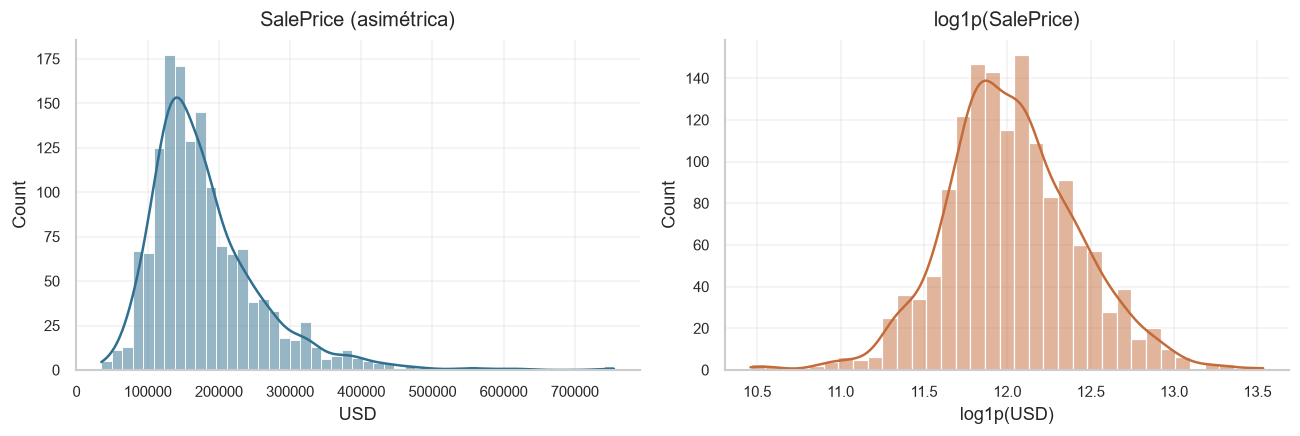

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(df_raw[TARGET_COL], kde=True, ax=axes[0], color=PLOT_PRIMARY)
style_axes(axes[0], "SalePrice (asimétrica)", "USD", "Count")
sns.histplot(np.log1p(df_raw[TARGET_COL]), kde=True, ax=axes[1], color=PLOT_SECONDARY)
style_axes(axes[1], "log1p(SalePrice)", "log1p(USD)", "Count")
finalize_figure()


In [26]:
print(
    f"Asimetría SalePrice: {df_raw[TARGET_COL].skew():.2f} | "
    f"log1p: {np.log1p(df_raw[TARGET_COL]).skew():.2f}"
)


Asimetría SalePrice: 1.88 | log1p: 0.12


## 4.0 Decisiones sobre variables temporales

La actividad pide una valuación **estática**: sin tendencias cronológicas absolutas.


### 4.1 `YrSold` — se elimina

`YrSold` solo toma unos pocos años de calendario (2006–2010). En un plano estático no aporta una característica intrínseca de la vivienda: captura coyuntura (p. ej. 2008). Incluirla contradice la restricción del enunciado. **Decisión: eliminar.**


### 4.2 `YearBuilt` / `YearRemodAdd` → `AgeHouse` / `AgeRemod`

Se convierten a edades relativas a **2026**:

- `AgeHouse = 2026 − YearBuilt`
- `AgeRemod = 2026 − YearRemodAdd`

Una edad se interpreta directo en valuación. **Las originales se eliminan**: son una transformación lineal exacta de las edades → colinealidad perfecta. El mismo criterio aplica a `GarageYrBlt` → `AgeGarage` (si no hay garaje queda NaN y se imputa dentro del pipeline).


### 4.3 `MoSold` — seno / coseno (cíclica)

El mes es circular: diciembre ≈ enero. Uso:

$$
MoSold\_sin = \sin(2\pi \cdot MoSold / 12),\quad
MoSold\_cos = \cos(2\pi \cdot MoSold / 12)
$$

**Se elimina el original** porque queda representado por el par (sin, cos).


In [27]:
outlier_mask: pd.Series = (df_raw["GrLivArea"] > OUTLIER_GRLIVAREA) & (
    df_raw[TARGET_COL] < OUTLIER_PRICE_MAX
)
print(
    f"Atípicos GrLivArea>{OUTLIER_GRLIVAREA} y precio bajo a eliminar: "
    f"{int(outlier_mask.sum())}"
)


Atípicos GrLivArea>4000 y precio bajo a eliminar: 2


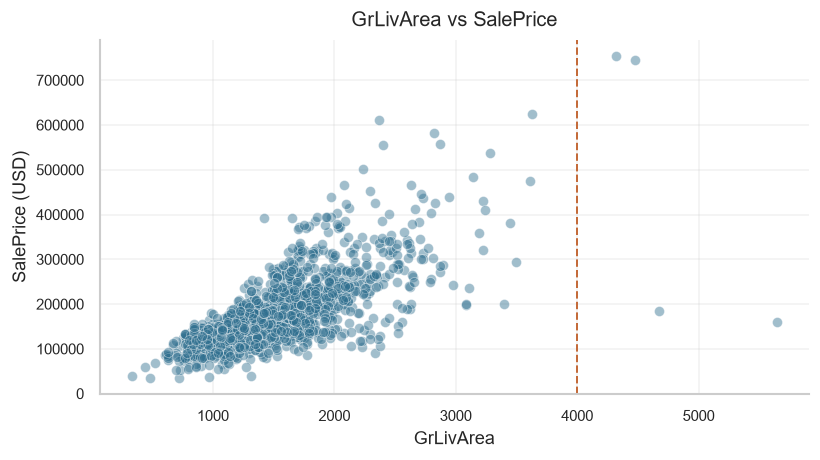

In [28]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(
    data=df_raw,
    x="GrLivArea",
    y=TARGET_COL,
    alpha=0.45,
    ax=ax,
    color=PLOT_PRIMARY,
)
ax.axvline(OUTLIER_GRLIVAREA, color=PLOT_SECONDARY, ls="--", lw=1.2)
style_axes(ax, "GrLivArea vs SalePrice", "GrLivArea", "SalePrice (USD)")
finalize_figure()


In [29]:
def drop_documented_outliers(frame: pd.DataFrame) -> pd.DataFrame:
    """
    Remove the two well-known GrLivArea outliers from the Ames dataset.
    """

    keep = ~(
        (frame["GrLivArea"] > OUTLIER_GRLIVAREA)
        & (frame[TARGET_COL] < OUTLIER_PRICE_MAX)
    )

    return frame.loc[keep].reset_index(drop=True).copy()


In [30]:
def add_temporal_features(
    frame: pd.DataFrame,
    *,
    current_year: int = CURRENT_YEAR,
) -> pd.DataFrame:
    """
    Static-valuation transforms: relative ages + cyclic month; drop calendar cols.
    """

    out = frame.copy()
    out["AgeHouse"] = current_year - out["YearBuilt"]
    out["AgeRemod"] = current_year - out["YearRemodAdd"]
    out["AgeGarage"] = current_year - out["GarageYrBlt"]
    out["MoSold_sin"] = np.sin(2 * np.pi * out["MoSold"] / 12)
    out["MoSold_cos"] = np.cos(2 * np.pi * out["MoSold"] / 12)
    out = out.drop(columns=list(DROP_COLS))
    out["MSSubClass"] = out["MSSubClass"].astype(str)

    return out


In [31]:
df: pd.DataFrame = add_temporal_features(drop_documented_outliers(df_raw))
print(f"Shape tras transformaciones temporales: {df.shape}")


Shape tras transformaciones temporales: (1458, 80)


In [32]:
df[["AgeHouse", "AgeRemod", "MoSold_sin", "MoSold_cos"]].describe().T


,count,mean,std,min,25%,50%,75%,max
AgeHouse,1458.000,54.782,30.194,16.000,26.000,53.500,72.000,154.000
AgeRemod,1458.000,41.166,20.642,16.000,22.000,32.000,59.000,76.000
MoSold_sin,1458.000,0.002,0.650,-1.000,-0.500,0.000,0.500,1.000
MoSold_cos,1458.000,-0.355,0.673,-1.000,-0.866,-0.500,0.000,1.000


## 5.0 Limpieza, imputación y tipología de variables


### 5.1 Datos perdidos semánticos vs. realmente faltantes

#### `PoolQC` y `GarageType` (pregunta 5)

Según `data_description.txt`, **`NA` en `PoolQC` significa “No Pool”** y **`NA` en `GarageType` significa “No Garage”**. No son fallos de captura aleatorios: son la forma en que el diccionario codifica la *ausencia* del elemento.

Lo confirmamos en `train.csv`:

- las **1,453** filas con `PoolQC` NA tienen **`PoolArea == 0`** (y al revés);
- las **81** filas con `GarageType` NA tienen **`GarageArea == 0`** y `GarageCars == 0`, y el resto de columnas de garaje (`GarageFinish`, `GarageQual`, `GarageCond`, `GarageYrBlt`) también vienen NA.

Por eso las rellenamos con la categoría explícita **`"None"`**. Imputar con la **moda** sería un error de dominio: inventaría albercas o garajes en casas que no los tienen y distorsionaría justo la señal que el mercado usa para valorar.

La misma lógica aplica a Alley, Fence, FireplaceQu, Bsmt* (cuando `TotalBsmtSF == 0`), GarageQual/Cond/Finish y MiscFeature. En cambio, si hay sótano/veneer real con etiqueta NA (p. ej. Ids 949 y 333 en sótano, o `MasVnrArea > 0` con tipo NA), ese NA **sí es faltante** y se deja para la moda del `Pipeline` en train.

#### Otras decisiones del punto 4 (log, atípicos, tipología)

- **`SalePrice` → `log1p`:** la distribución es asimétrica a la derecha (asimetría ≈ 1.9; tras `log1p` ≈ 0.1). El log estabiliza la varianza y ayuda a lineales, SVR y MLP; las métricas se reportan en dólares con `expm1`.
- **Atípicos:** se eliminan **2** casas con `GrLivArea > 4000` y precio < $300,000 (anomalías documentadas del dataset Ames/Kaggle) que sesgan la frontera de regresión.
- **`MSSubClass`:** es un código de tipología (20, 60, 120…), no una cantidad → se trata como nominal (string).
- **`LotFrontage`:** faltante real; se imputa con mediana por `Neighborhood` aprendida solo en el fold de train (`NeighborhoodLotFrontageImputer`), con respaldo a la mediana global.


In [33]:
def _fill_none(frame: pd.DataFrame, column: str, mask: pd.Series) -> None:
    """
    In-place: set NA to 'None' only on rows where mask is True.
    """

    frame.loc[mask, column] = frame.loc[mask, column].fillna("None")


In [34]:
def fill_semantic_absence(frame: pd.DataFrame) -> pd.DataFrame:
    """
    Recode dictionary NA (= feature absent) to the category 'None'.
    """

    out = frame.copy()

    no_garage = out["GarageArea"].fillna(0).eq(0)
    for col in GARAGE_CAT_COLS:
        _fill_none(out, col, no_garage)

    no_bsmt = out["TotalBsmtSF"].fillna(0).eq(0)
    for col in BSMT_CAT_COLS:
        _fill_none(out, col, no_bsmt)

    _fill_none(out, "PoolQC", out["PoolArea"].fillna(0).eq(0))
    _fill_none(out, "FireplaceQu", out["Fireplaces"].fillna(0).eq(0))
    out["Alley"] = out["Alley"].fillna("None")
    out["Fence"] = out["Fence"].fillna("None")
    out["MiscFeature"] = out["MiscFeature"].fillna("None")

    out["MasVnrArea"] = out["MasVnrArea"].fillna(0)
    _fill_none(out, "MasVnrType", out["MasVnrArea"].eq(0))

    return out


In [35]:
df = fill_semantic_absence(df)
print(
    "Semántica None | PoolQC:",
    int((df["PoolQC"] == "None").sum()),
    "| GarageType:",
    int((df["GarageType"] == "None").sum()),
    "| BsmtQual:",
    int((df["BsmtQual"] == "None").sum()),
)


Semántica None | PoolQC: 1452 | GarageType: 81 | BsmtQual: 37


In [36]:
display(missing_table(df, head=None))


,faltantes,pct
LotFrontage,259,17.760
AgeGarage,81,5.560
MasVnrType,5,0.340
BsmtExposure,1,0.070
BsmtFinType2,1,0.070
Electrical,1,0.070


### 5.2 Criterios de transformación

| Tipo      | Imputación (_fit_ solo en train)                     | Transformación                             | Por qué                        |
| --------- | ---------------------------------------------------- | ------------------------------------------ | ------------------------------ |
| Numéricas | Mediana (+ `LotFrontage` por vecindario) + indicador | `StandardScaler` en lineales/SVM/MLP       | Mediana robusta                |
| Ordinales | Moda si queda NA real                                | `OrdinalEncoder` con orden del diccionario | Respeta Po < Fa < TA < Gd < Ex |
| Nominales | Moda                                                 | One-Hot (`drop` según modelo; §6)          | Sin orden natural              |
| Objetivo  | —                                                    | `log1p` vía `TransformedTargetRegressor`   | Métricas en USD (`expm1`)      |

`MSSubClass` es código de tipología → nominal (string). `OverallQual` / `OverallCond` ya vienen como enteros 1–10.


In [37]:
QUAL_LEVELS: Final[list[str]] = ["None", "Po", "Fa", "TA", "Gd", "Ex"]

In [38]:
ORD_MAP: Final[dict[str, list[str]]] = {
    **{
        c: QUAL_LEVELS
        for c in [
            "ExterQual",
            "ExterCond",
            "BsmtQual",
            "BsmtCond",
            "HeatingQC",
            "KitchenQual",
            "FireplaceQu",
            "GarageQual",
            "GarageCond",
            "PoolQC",
        ]
    },
    "BsmtExposure": ["None", "No", "Mn", "Av", "Gd"],
    "BsmtFinType1": ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "BsmtFinType2": ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "GarageFinish": ["None", "Unf", "RFn", "Fin"],
    "Functional": ["Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
    "LotShape": ["IR3", "IR2", "IR1", "Reg"],
    "LandSlope": ["Sev", "Mod", "Gtl"],
    "PavedDrive": ["N", "P", "Y"],
    "CentralAir": ["N", "Y"],
    "Fence": ["None", "MnWw", "GdWo", "MnPrv", "GdPrv"],
}


In [39]:
X: pd.DataFrame = df.drop(columns=TARGET_COL)
y: pd.Series = df[TARGET_COL]


In [40]:
ord_cols: list[str] = list(ORD_MAP)
for col in ord_cols:
    unseen = set(X[col].dropna().unique()) - set(ORD_MAP[col])
    assert not unseen, f"{col}: valores fuera de escala {unseen}"


In [41]:
nom_cols: list[str] = [
    c for c in X.select_dtypes(exclude="number").columns if c not in ord_cols
]
num_cols: list[str] = X.select_dtypes(include="number").columns.tolist()
print(f"{len(num_cols)} numéricas | {len(ord_cols)} ordinales | {len(nom_cols)} nominales")


35 numéricas | 20 ordinales | 24 nominales


## 6.0 One-Hot Encoding y el parámetro `drop`

- **No árboles** (OLS, Ridge/Lasso, SVR, MLP): `drop="first"` evita la trampa de dummies.
- **Árboles** (DT, RF, XGBoost): `drop=None`. No sufren la misma colinealidad; dropear una categoría diluye importancias.


In [42]:
class NeighborhoodLotFrontageImputer(BaseEstimator, TransformerMixin):
    """
    Impute LotFrontage with the neighborhood median learned on the fit fold.
    """

    def fit(
        self,
        X: pd.DataFrame,
        y: Any = None,
    ) -> NeighborhoodLotFrontageImputer:
        frame = X if isinstance(X, pd.DataFrame) else pd.DataFrame(X)
        self.neigh_medians_: pd.Series = (
            frame.groupby("Neighborhood")["LotFrontage"].median()
        )
        self.global_median_: float = float(frame["LotFrontage"].median())

        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        frame = (X if isinstance(X, pd.DataFrame) else pd.DataFrame(X)).copy()
        filled = frame["LotFrontage"].copy()
        for neigh, median in self.neigh_medians_.items():
            mask = frame["Neighborhood"].eq(neigh) & filled.isna()
            filled.loc[mask] = median
        frame["LotFrontage"] = filled.fillna(self.global_median_)

        return frame


In [43]:
def build_prep(*, tree: bool = False) -> ColumnTransformer:
    """
    tree=True  -> no scaling, full One-Hot.
    tree=False -> StandardScaler on num/ord + drop='first' on nominals.
    """

    scale: list[Any] = [] if tree else [StandardScaler()]
    num = make_pipeline(
        SimpleImputer(strategy="median", add_indicator=True),
        *scale,
    )
    ordi = make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OrdinalEncoder(
            categories=[ORD_MAP[c] for c in ord_cols],
            handle_unknown="use_encoded_value",
            unknown_value=-1,
        ),
        *scale,
    )
    nom = make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(
            drop=None if tree else "first",
            handle_unknown="ignore",
            sparse_output=False,
        ),
    )

    return ColumnTransformer(
        [
            ("num", num, num_cols),
            ("ord", ordi, ord_cols),
            ("nom", nom, nom_cols),
        ],
        verbose_feature_names_out=False,
    )


In [44]:
def make_estimator(
    model: Any,
    *,
    tree: bool = False,
) -> TransformedTargetRegressor:
    """
    LotFrontage group-impute + prep + model; target in log1p, preds in USD.
    """

    pipe = Pipeline(
        [
            ("lot_frontage", NeighborhoodLotFrontageImputer()),
            ("prep", build_prep(tree=tree)),
            ("model", model),
        ]
    )

    return TransformedTargetRegressor(
        regressor=pipe,
        func=np.log1p,
        inverse_func=np.expm1,
        check_inverse=False,
    )


## 7.0 Partición de los datos

Partimos **solo** el `train.csv` de Kaggle (el `test.csv` oficial no trae `SalePrice`).

- **80 %** → `X_train` / `y_train` (ajuste + CV de 5 folds)
- **20 %** → `X_val` / `y_val` (**validación hold-out**; no se usa para elegir hiperparámetros)

`VAL_SIZE = 0.20` y `SPLIT_CFG.val_size`. El parámetro de sklearn sigue llamándose `test_size`, pero en este notebook esa fracción es nuestra **val**, no el test de Kaggle.


In [45]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=SPLIT_CFG.val_size,
    random_state=SPLIT_CFG.random_state,
)

cv = KFold(
    n_splits=CV_CFG.n_splits,
    shuffle=CV_CFG.shuffle,
    random_state=CV_CFG.random_state,
)

print(f"train: {X_train.shape} | val: {X_val.shape}")


train: (1166, 79) | val: (292, 79)


## 8.0 Modelo base (ingenuo)

Predice siempre la **media** (y, como referencia, la mediana) del precio en train.


In [46]:
base_mean = DummyRegressor(strategy="mean").fit(X_train, y_train)
base_median = DummyRegressor(strategy="median").fit(X_train, y_train)

In [47]:
RMSE_BASE: float = rmse(y_val, base_mean.predict(X_val))
print(f"RMSE ingenuo (media):   ${RMSE_BASE:,.0f}")
print(f"RMSE ingenuo (mediana): ${rmse(y_val, base_median.predict(X_val)):,.0f}")
print(
    f"MAE  ingenuo (media):   "
    f"${mean_absolute_error(y_val, base_mean.predict(X_val)):,.0f}"
)


RMSE ingenuo (media):   $74,324
RMSE ingenuo (mediana): $76,742
MAE  ingenuo (media):   $57,980


## 9.0 Entrenamiento y ajuste de hiperparámetros

Cada familia se ajusta por separado con búsqueda sobre **train** (CV, scoring RMSE). Luego:

- **CV_RMSE / CV_MAE**: predicciones *out-of-fold* en train → sirven para **elegir** modelos sin mirar val. Ojo: como los hiperparámetros se eligieron con esos mismos folds, el CV reportado es ligeramente **optimista**.
- **RMSE / MAE / R² / MAPE (val)**: desempeño en val (hold-out) no sesgado para comparar y para el reporte.
- **Curva de aprendizaje** en USD.


In [48]:
RESULTS: list[dict[str, Any]] = []
BEST: dict[str, Any] = {}
FITTED: dict[str, Any] = {}


In [49]:
def results_frame() -> pd.DataFrame:
    return pd.DataFrame(RESULTS)


In [50]:
def plot_learning_curve(estimator: Any, name: str) -> None:
    sizes, tr, va = learning_curve(
        estimator,
        X_train,
        y_train,
        cv=cv,
        scoring=CV_CFG.scoring,
        train_sizes=np.linspace(0.2, 1.0, 5),
        n_jobs=SEARCH_CFG.n_jobs,
        shuffle=True,
        random_state=SEARCH_CFG.random_state,
    )
    tr_scores, va_scores = -tr, -va
    tr_end = float(tr_scores.mean(1)[-1])
    va_end = float(va_scores.mean(1)[-1])
    print(
        f"LC {name} | n_final={int(sizes[-1])} | "
        f"RMSE train ${tr_end:,.0f} | RMSE CV ${va_end:,.0f} | "
        f"brecha ${va_end - tr_end:,.0f}"
    )

    fig, ax = plt.subplots(figsize=(6.2, 4))
    ax.plot(
        sizes,
        tr_scores.mean(1),
        "o-",
        color=PLOT_PRIMARY,
        label="Entrenamiento",
    )
    ax.fill_between(
        sizes,
        tr_scores.mean(1) - tr_scores.std(1),
        tr_scores.mean(1) + tr_scores.std(1),
        alpha=0.15,
        color=PLOT_PRIMARY,
    )
    ax.plot(
        sizes,
        va_scores.mean(1),
        "o-",
        color=PLOT_SECONDARY,
        label="CV sobre train",
    )
    ax.fill_between(
        sizes,
        va_scores.mean(1) - va_scores.std(1),
        va_scores.mean(1) + va_scores.std(1),
        alpha=0.15,
        color=PLOT_SECONDARY,
    )
    ymax = float(
        max(3 * np.nanmax(va_scores.mean(1)), np.nanmax(tr_scores.mean(1)) * 1.05)
    )
    if np.isfinite(ymax) and ymax > 0:
        ax.set_ylim(0, ymax)
    style_axes(
        ax,
        f"Curva de aprendizaje — {name}",
        "Tamaño de entrenamiento",
        "RMSE (USD)",
    )
    ax.legend()
    finalize_figure()


In [51]:
def add_result(
    name: str,
    best: Any,
    search_time: float = np.nan,
    params: Any = "",
    *,
    do_cv: bool = True,
) -> Any:
    final = clone(best)
    t0 = time.perf_counter()
    final.fit(X_train, y_train)
    fit_time = time.perf_counter() - t0
    pred = final.predict(X_val)

    row: dict[str, Any] = {"Modelo": name}
    if do_cv:
        oof = cross_val_predict(
            clone(best),
            X_train,
            y_train,
            cv=cv,
            n_jobs=SEARCH_CFG.n_jobs,
        )
        row["CV_RMSE"] = rmse(y_train, oof)
        row["CV_MAE"] = float(mean_absolute_error(y_train, oof))
    else:
        row["CV_RMSE"] = np.nan
        row["CV_MAE"] = np.nan

    row.update(regression_metrics(y_val, pred))
    row["Tiempo_fit_s"] = fit_time
    row["Tiempo_busqueda_s"] = search_time
    row["Mejores_hiperparametros"] = str(params)

    RESULTS.append(row)
    BEST[name] = best
    FITTED[name] = final

    return final


In [52]:
def run_model(
    name: str,
    model: Any,
    params: dict[str, list[Any]] | None = None,
    *,
    tree: bool = False,
    search: str = "random",
    n_iter: int = 20,
) -> Any:
    estimator = make_estimator(model, tree=tree)
    t0 = time.perf_counter()
    best_params: dict[str, Any] = {}

    if params:
        grid = {f"regressor__model__{k}": v for k, v in params.items()}
        cv_kw: dict[str, Any] = {
            "cv": cv,
            "scoring": CV_CFG.scoring,
            "n_jobs": SEARCH_CFG.n_jobs,
            "refit": True,
        }
        if search == "grid" and not SEARCH_CFG.quick:
            searcher: Any = GridSearchCV(estimator, grid, **cv_kw)
        else:
            searcher = RandomizedSearchCV(
                estimator,
                grid,
                n_iter=2 if SEARCH_CFG.quick else n_iter,
                random_state=SEARCH_CFG.random_state,
                **cv_kw,
            )
        searcher.fit(X_train, y_train)
        estimator = searcher.best_estimator_
        best_params = {
            k.removeprefix("regressor__model__"): v
            for k, v in searcher.best_params_.items()
        }
        print(f"Mejores hiperparámetros: {best_params}")
        print(f"RMSE CV (búsqueda): ${-searcher.best_score_:,.0f}")

    search_time = time.perf_counter() - t0
    add_result(name, estimator, search_time, best_params)
    plot_learning_curve(estimator, name)
    display(
        results_frame()
        .set_index("Modelo")
        .loc[[name], list(RESULT_METRIC_COLS)]
        .round(3)
    )

    return FITTED[name]


### 9.1 Regresión lineal múltiple (OLS, Ridge, Lasso)


LC OLS | n_final=932 | RMSE train $15,868 | RMSE CV $23,087 | brecha $7,219


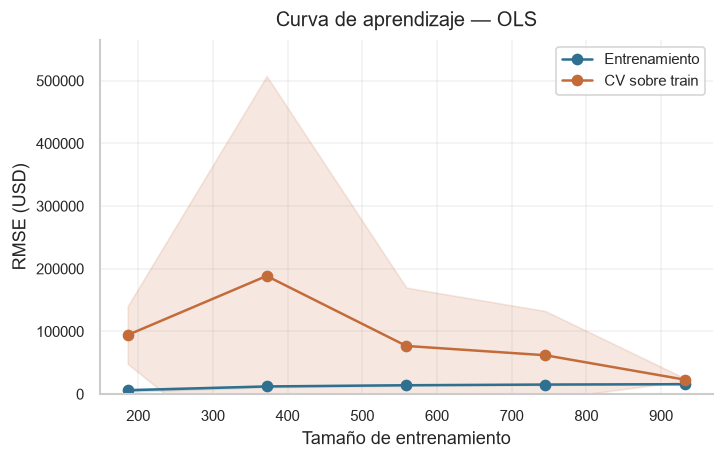

,CV_RMSE,CV_MAE,RMSE_val,MAE_val,R2_val,MAPE_val_%,Tiempo_fit_s
Modelo,,,,,,,
OLS,23174.950,14993.884,22604.542,15509.009,0.907,9.240,0.083


,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...egression())])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",False
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
Name,Type,Value
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step...egression())])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('lot_frontage', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None


In [53]:
run_model("OLS", LinearRegression())


Mejores hiperparámetros: {'alpha': 10}
RMSE CV (búsqueda): $20,868
LC Ridge | n_final=932 | RMSE train $17,203 | RMSE CV $20,874 | brecha $3,671


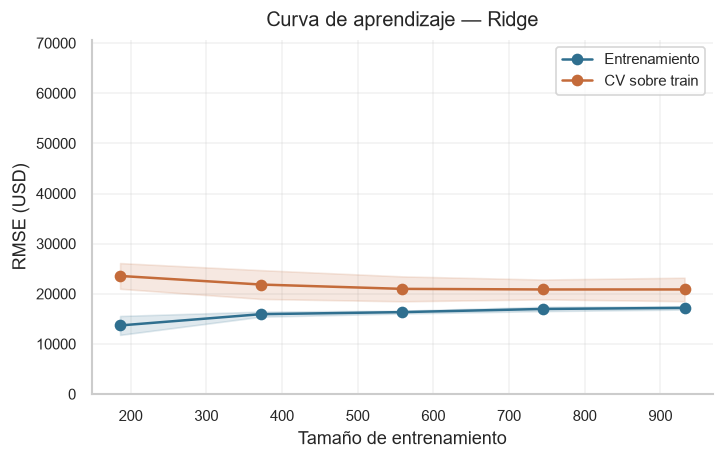

,CV_RMSE,CV_MAE,RMSE_val,MAE_val,R2_val,MAPE_val_%,Tiempo_fit_s
Modelo,,,,,,,
Ridge,21002.522,13768.846,20076.748,14174.587,0.927,8.672,0.090


,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...m_state=42))])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",False
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
Name,Type,Value
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step...m_state=42))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('lot_frontage', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None


In [54]:
run_model(
    "Ridge",
    Ridge(random_state=SEED),
    {"alpha": [0.1, 0.3, 1, 3, 10, 30, 100, 300]},
    search="grid",
)


Mejores hiperparámetros: {'alpha': 0.001}
RMSE CV (búsqueda): $20,566
LC Lasso | n_final=932 | RMSE train $18,444 | RMSE CV $20,574 | brecha $2,130


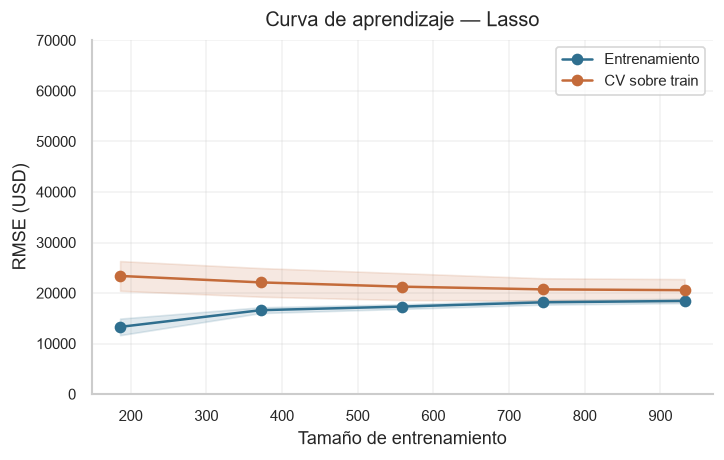

,CV_RMSE,CV_MAE,RMSE_val,MAE_val,R2_val,MAPE_val_%,Tiempo_fit_s
Modelo,,,,,,,
Lasso,20685.693,13781.963,19516.008,13881.468,0.931,8.517,0.118


,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...m_state=42))])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",False
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
Name,Type,Value
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step...m_state=42))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('lot_frontage', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None


In [55]:
run_model(
    "Lasso",
    Lasso(max_iter=20_000, random_state=SEED),
    {"alpha": [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2]},
    search="grid",
)


### 9.2 Árbol de decisión


Mejores hiperparámetros: {'min_samples_split': 2, 'min_samples_leaf': 5, 'max_depth': 10, 'ccp_alpha': 0.0001}
RMSE CV (búsqueda): $36,031
LC Arbol | n_final=932 | RMSE train $22,765 | RMSE CV $36,036 | brecha $13,270


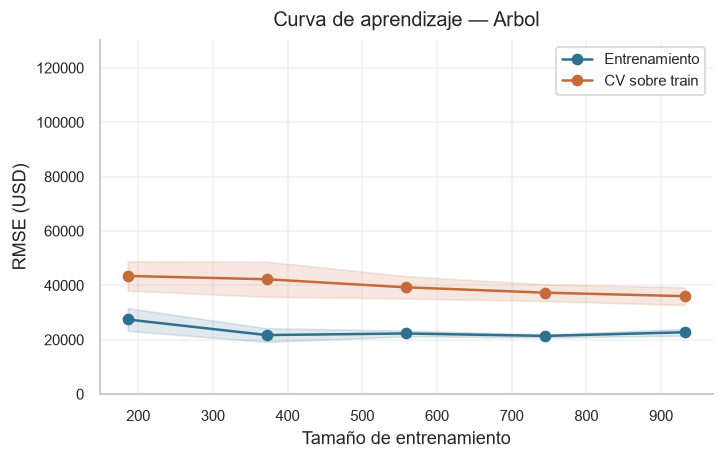

,CV_RMSE,CV_MAE,RMSE_val,MAE_val,R2_val,MAPE_val_%,Tiempo_fit_s
Modelo,,,,,,,
Arbol,36181.731,24342.495,36118.802,24637.003,0.764,14.624,0.120


,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...m_state=42))])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",False
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
Name,Type,Value
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step...m_state=42))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('lot_frontage', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None


In [56]:
run_model(
    "Arbol",
    DecisionTreeRegressor(random_state=SEED),
    {
        "max_depth": [3, 4, 5, 6, 8, 10, 12, None],
        "min_samples_leaf": [1, 3, 5, 10, 20],
        "min_samples_split": [2, 5, 10, 20],
        "ccp_alpha": [0, 1e-5, 1e-4, 1e-3],
    },
    tree=True,
    n_iter=30,
)


### 9.3 Bosque aleatorio


Mejores hiperparámetros: {'n_estimators': 400, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': None}
RMSE CV (búsqueda): $27,464
LC RF | n_final=932 | RMSE train $10,897 | RMSE CV $27,429 | brecha $16,531


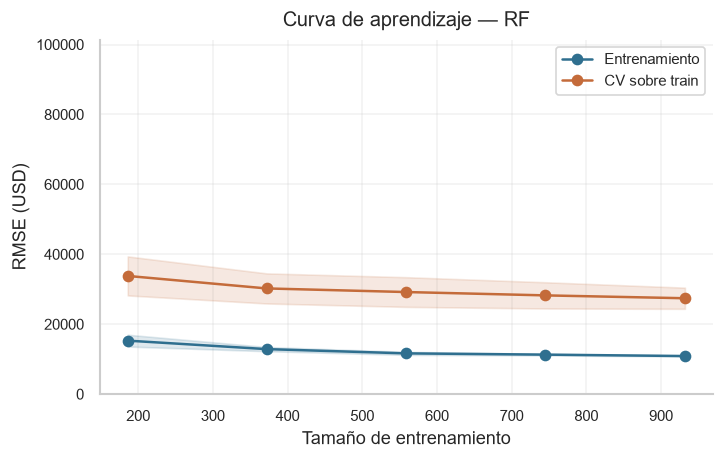

,CV_RMSE,CV_MAE,RMSE_val,MAE_val,R2_val,MAPE_val_%,Tiempo_fit_s
Modelo,,,,,,,
RF,27614.892,16604.097,22658.297,15690.609,0.907,9.697,4.198


,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...m_state=42))])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",False
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
Name,Type,Value
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step...m_state=42))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('lot_frontage', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None


In [57]:
run_model(
    "RF",
    RandomForestRegressor(random_state=SEED, n_jobs=1),
    {
        "n_estimators": [200, 400],
        "max_depth": [None, 10, 20],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", 0.3, 0.5],
    },
    tree=True,
    n_iter=12,
)


### 9.4 XGBoost


Mejores hiperparámetros: {'subsample': 0.8, 'reg_lambda': 0.5, 'n_estimators': 600, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.8}
RMSE CV (búsqueda): $23,267
LC XGB | n_final=932 | RMSE train $6,583 | RMSE CV $23,640 | brecha $17,057


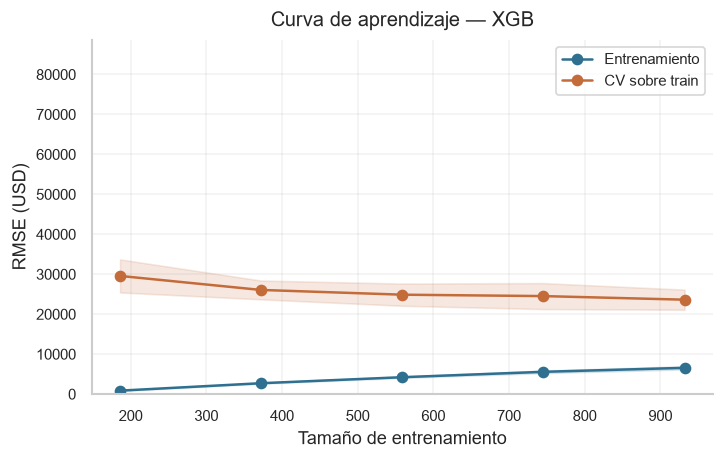

,CV_RMSE,CV_MAE,RMSE_val,MAE_val,R2_val,MAPE_val_%,Tiempo_fit_s
Modelo,,,,,,,
XGB,23444.119,14477.938,20156.381,14229.454,0.926,8.283,1.053


,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.","Pipeline(step...=None, ...))])"
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",False
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
Name,Type,Value
regressor_ regressor_: objectFitted regressor.,Pipeline,"Pipeline(step...=None, ...))])"
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('lot_frontage', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None


In [58]:
run_model(
    "XGB",
    XGBRegressor(tree_method="hist", random_state=SEED, n_jobs=1),
    {
        "n_estimators": [300, 600, 1000],
        "learning_rate": [0.01, 0.03, 0.05, 0.1],
        "max_depth": [2, 3, 4, 5],
        "subsample": [0.6, 0.8, 1.0],
        "colsample_bytree": [0.4, 0.6, 0.8],
        "min_child_weight": [1, 3, 5],
        "reg_lambda": [0.5, 1, 5, 10],
    },
    tree=True,
    n_iter=25,
)


### 9.5 Perceptrón multicapa (MLP)


Mejores hiperparámetros: {'learning_rate_init': 0.01, 'hidden_layer_sizes': (128,), 'alpha': 0.01, 'activation': 'tanh'}
RMSE CV (búsqueda): $33,571
LC MLP | n_final=932 | RMSE train $20,864 | RMSE CV $32,487 | brecha $11,623


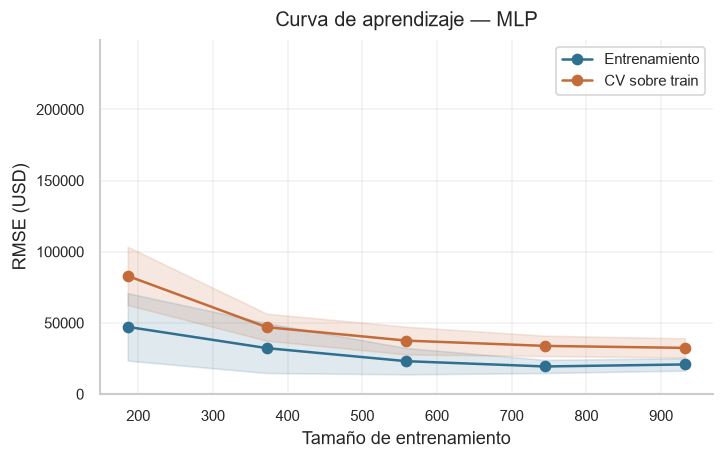

,CV_RMSE,CV_MAE,RMSE_val,MAE_val,R2_val,MAPE_val_%,Tiempo_fit_s
Modelo,,,,,,,
MLP,34073.914,20356.542,26641.326,17524.062,0.872,10.047,2.299


,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...ction=0.15))])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",False
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
Name,Type,Value
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step...ction=0.15))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('lot_frontage', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None


In [59]:
run_model(
    "MLP",
    MLPRegressor(
        solver="adam",
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=20,
        max_iter=1000,
        random_state=SEED,
    ),
    {
        "hidden_layer_sizes": [(64,), (128,), (64, 32), (128, 64)],
        "alpha": [1e-4, 1e-3, 1e-2, 1e-1, 1],
        "learning_rate_init": [1e-3, 3e-3, 1e-2],
        "activation": ["relu", "tanh"],
    },
    n_iter=15,
)


### 9.6 Máquina de vector soporte (SVR)


Mejores hiperparámetros: {'gamma': 0.0003, 'epsilon': 0.01, 'C': 30}
RMSE CV (búsqueda): $20,922
LC SVR | n_final=932 | RMSE train $15,239 | RMSE CV $20,919 | brecha $5,679


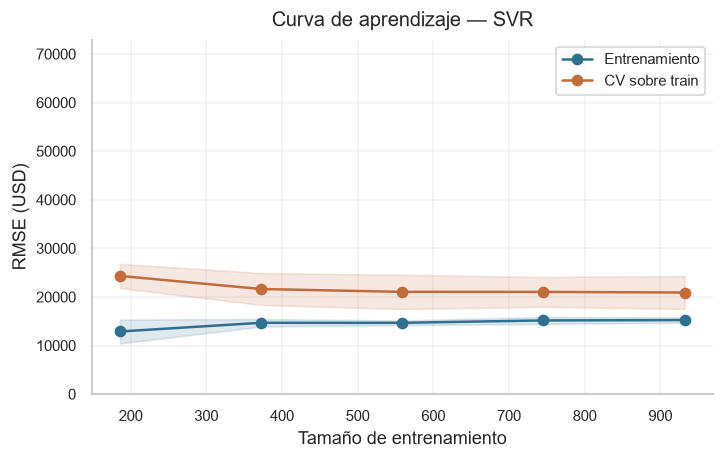

,CV_RMSE,CV_MAE,RMSE_val,MAE_val,R2_val,MAPE_val_%,Tiempo_fit_s
Modelo,,,,,,,
SVR,21196.880,13085.913,18087.242,12628.387,0.941,8.044,0.262


,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...mma=0.0003))])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",False
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
Name,Type,Value
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step...mma=0.0003))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('lot_frontage', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None


In [60]:
run_model(
    "SVR",
    SVR(kernel="rbf"),
    {
        "C": [0.3, 1, 3, 10, 30, 100],
        "epsilon": [0.01, 0.03, 0.1],
        "gamma": ["scale", 0.0003, 0.001, 0.003],
    },
    n_iter=20,
)

### 9.7 Tabla resumen de modelos individuales


In [61]:
res = results_frame()
cols = ["Modelo", *RESULT_METRIC_COLS, "Tiempo_busqueda_s"]
print(f"Referencia — RMSE ingenuo en val (hold-out): ${RMSE_BASE:,.0f}")
display(res[cols].sort_values("CV_RMSE").round(3).reset_index(drop=True))


Referencia — RMSE ingenuo en val (hold-out): $74,324


,Modelo,CV_RMSE,CV_MAE,RMSE_val,MAE_val,R2_val,MAPE_val_%,Tiempo_fit_s,Tiempo_busqueda_s
0,Lasso,20685.693,13781.963,19516.008,13881.468,0.931,8.517,0.118,1.098
1,Ridge,21002.522,13768.846,20076.748,14174.587,0.927,8.672,0.090,1.059
2,SVR,21196.880,13085.913,18087.242,12628.387,0.941,8.044,0.262,4.583
3,OLS,23174.950,14993.884,22604.542,15509.009,0.907,9.240,0.083,0.000
4,XGB,23444.119,14477.938,20156.381,14229.454,0.926,8.283,1.053,17.277
5,RF,27614.892,16604.097,22658.297,15690.609,0.907,9.697,4.198,26.636
6,MLP,34073.914,20356.542,26641.326,17524.062,0.872,10.047,2.299,28.745
7,Arbol,36181.731,24342.495,36118.802,24637.003,0.764,14.624,0.120,3.510


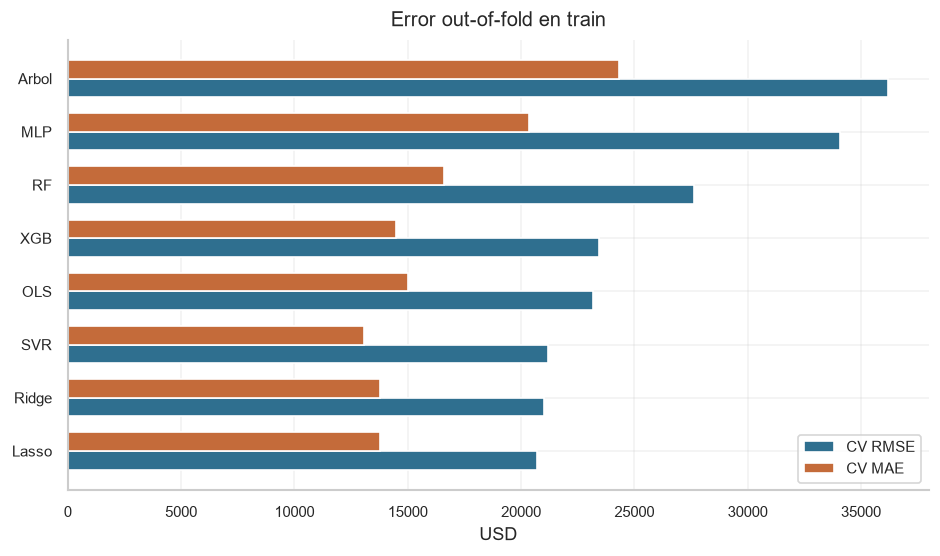

In [62]:
plot_df = res.sort_values("CV_RMSE")
fig, ax = plt.subplots(figsize=(8, 4.8))
y_pos = np.arange(len(plot_df))
height = 0.35
ax.barh(
    y_pos - height / 2,
    plot_df["CV_RMSE"],
    height,
    color=PLOT_PRIMARY,
    edgecolor=PLOT_EDGE,
    label="CV RMSE",
)
ax.barh(
    y_pos + height / 2,
    plot_df["CV_MAE"],
    height,
    color=PLOT_SECONDARY,
    edgecolor=PLOT_EDGE,
    label="CV MAE",
)
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df["Modelo"])
style_axes(ax, "Error out-of-fold en train", "USD", "")
ax.legend()
finalize_figure()


**Lectura de las curvas de esta corrida**

Anclamos el extremo de **CV** a la tabla de §9.7; la brecha train–CV se lee en cada figura (y, tras re-ejecutar, en el print `LC …` bajo la curva). La etiqueta del plot es **CV sobre train**, no el hold-out `X_val`.

- **OLS / Ridge / Lasso:** train y CV se acercan al final (brecha chica en la figura). Curvas casi planas cerca del máximo de filas: más datos del mismo tipo aportarían poco. CV_RMSE tabla: Lasso **$20,686**, Ridge **$21,003**.
- **SVR:** CV al final **~$21.2k** (tabla); en la figura el train queda por debajo con brecha moderada y estable. También se aplana. Es el mejor en val (**$18,087**).
- **Árbol:** sobreajuste claro — CV_RMSE **$36,182** y en la figura el train mucho más bajo (brecha grande). El CV baja poco al añadir datos.
- **RF / XGB:** CV **~$27.6k / ~$23.4k** con train muy por debajo en la figura (varianza alta). Algo de pendiente residual en CV sugiere que más datos ayudarían un poco; el gap de sobreajuste domina.
- **MLP:** en la figura el CV arranca alto y baja al crecer la muestra hasta **~$34.1k** (tabla), aún por encima de SVR/Lasso; conserva brecha train–CV visible.

**Nota metodológica:** el CV_RMSE de la tabla es ligeramente **optimista** porque los hiperparámetros se eligieron con los mismos folds. El número no sesgado para comparar despliegue es el **RMSE/MAE de val**.


## 10.0 Análisis de factores (Lasso)

**Criterio de “mejor” aquí:** el modelo con **menor CV_RMSE** individual → **Lasso** ($20,686). Lo usamos para el análisis de factores porque es lineal, interpretable y está a ~$500 de SVR en CV RMSE (y a ~$1,400 en val sobre 292 casas: diferencia plausible, no un veredicto cerrado).

Más abajo, la selección de top-3 para ensembles usa **CV (RMSE+MAE)**, donde gana **SVR**; en val SVR también es el mejor predictor. En el reporte técnico recomendamos **SVR por desempeño** y mencionamos Lasso como alternativa simple/explicable.


In [63]:
# Factor analysis: lowest CV_RMSE among individuals (interpretable linear model).
best_name: str = results_frame().sort_values("CV_RMSE").iloc[0]["Modelo"]
print(
    f"Modelo para análisis de factores (menor CV_RMSE): {best_name} "
    "(SVR gana en val / RMSE+MAE; ver §11 y §13)"
)


Modelo para análisis de factores (menor CV_RMSE): Lasso (SVR gana en val / RMSE+MAE; ver §11 y §13)


In [64]:
pi = permutation_importance(
    FITTED[best_name],
    X_val,
    y_val,
    scoring="neg_root_mean_squared_error",
    n_repeats=5,
    random_state=SEED,
    n_jobs=N_JOBS,
)
imp = pd.Series(pi.importances_mean, index=X_val.columns).sort_values(
    ascending=False
)
top = imp.head(15).iloc[::-1]


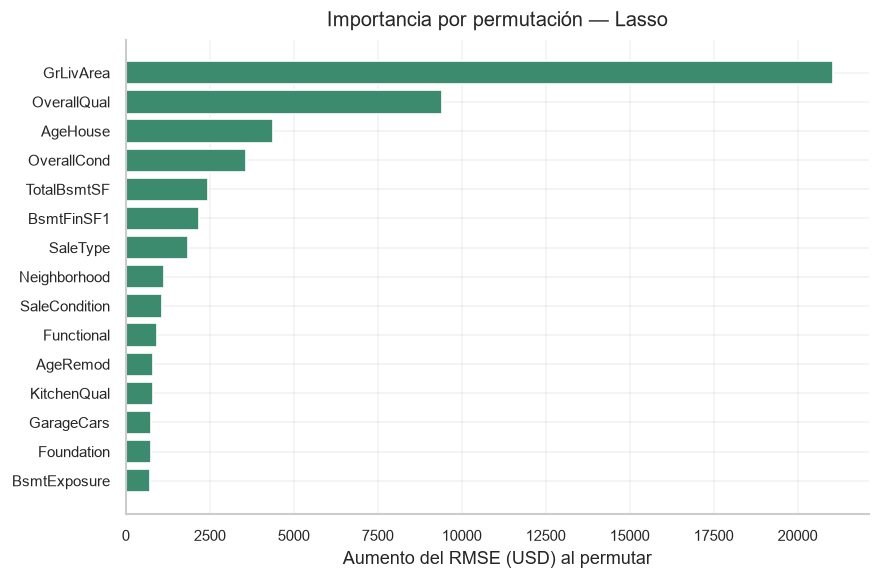

,delta_RMSE_USD
GrLivArea,21068.000
OverallQual,9415.000
AgeHouse,4394.000
OverallCond,3580.000
TotalBsmtSF,2432.000
BsmtFinSF1,2183.000
SaleType,1865.000
Neighborhood,1144.000
SaleCondition,1088.000
Functional,943.000


In [65]:
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(top.index, top.values, color=PLOT_ACCENT, edgecolor=PLOT_EDGE)
style_axes(
    ax,
    f"Importancia por permutación — {best_name}",
    "Aumento del RMSE (USD) al permutar",
    "",
)
finalize_figure()
display(imp.head(15).round(0).to_frame("delta_RMSE_USD"))


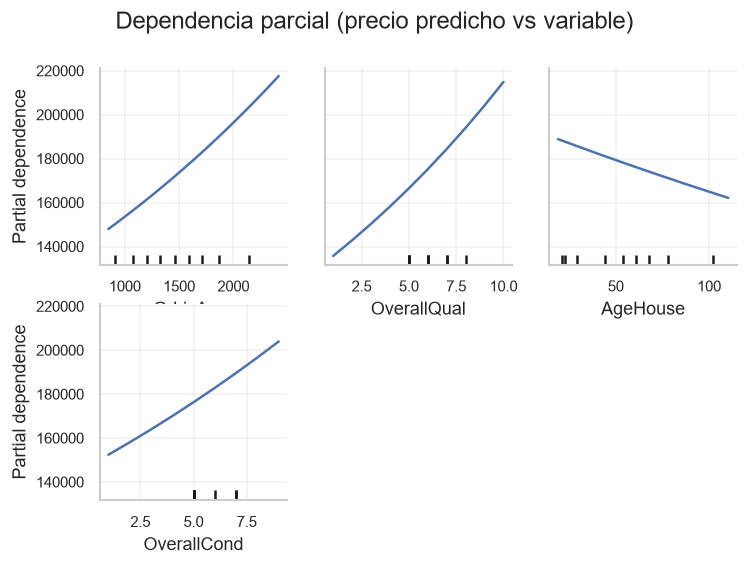

In [66]:
top_num = [c for c in imp.index if c in num_cols][:4]
X_pd = X_train.copy()
X_pd[top_num] = X_pd[top_num].astype(float)
PartialDependenceDisplay.from_estimator(
    FITTED[best_name],
    X_pd,
    top_num,
    grid_resolution=30,
    n_jobs=1,
)
plt.suptitle("Dependencia parcial (precio predicho vs variable)")
plt.tight_layout()
plt.show()


### Interpretación en contexto inmobiliario (esta corrida, Lasso)

La importancia por permutación sobre val (aumento del RMSE al desordenar cada variable) ordena así los primeros factores. **ΔRMSE ≥ 0 siempre**: mide sensibilidad del error, no el signo del efecto sobre el precio.

| Rank | Variable | Δ RMSE (USD) | Lectura de negocio |
| --- | --- | ---: | --- |
| 1 | `GrLivArea` | +$21,068 | Metros habitables sobre rasante: el driver dominante del modelo. |
| 2 | `OverallQual` | +$9,415 | Calidad global de materiales/acabados. |
| 3 | `AgeHouse` | +$4,394 | Edad de la vivienda (ref. 2026): señal estructural fuerte para el error de predicción. |
| 4 | `OverallCond` | +$3,580 | Condición de mantenimiento, distinta de la calidad de acabados. |
| 5–6 | `TotalBsmtSF`, `BsmtFinSF1` | +$2.4k / +$2.2k | Área y acabado de sótano. |
| 7–9 | `SaleType`, `Neighborhood`, `SaleCondition` | +$1.9k / +$1.1k / +$1.1k | **Tipo y condición de la transacción** entran en el top 10 junto con la zona: no son solo atributos físicos de la casa. |

También aparecen `Functional`, `AgeRemod`, `KitchenQual` y `GarageCars`. La estacionalidad (`MoSold_sin/cos`) no entra en este top 15.

Limitación: la importancia se reparte entre variables correlacionadas (p. ej. áreas) y mide asociación, no causalidad ni dirección del precio. Analizamos Lasso por CV_RMSE e interpretabilidad; el mejor predictor en val es SVR (§11).


## 11.0 Tres mejores modelos con RMSE + MAE

La suma se calcula con métricas **CV (OOF)** para no usar val en la selección.


In [67]:
res = results_frame()
res["CV_RMSE+MAE"] = res["CV_RMSE"] + res["CV_MAE"]
rank = (
    res.sort_values("CV_RMSE+MAE")[
        ["Modelo", "CV_RMSE", "CV_MAE", "CV_RMSE+MAE", "RMSE_val", "MAE_val"]
    ]
    .round(0)
    .reset_index(drop=True)
)
top3: list[str] = rank["Modelo"].head(3).tolist()
print("Tres mejores modelos:", top3)
display(rank)


Tres mejores modelos: ['SVR', 'Lasso', 'Ridge']


,Modelo,CV_RMSE,CV_MAE,CV_RMSE+MAE,RMSE_val,MAE_val
0,SVR,21197.000,13086.000,34283.000,18087.000,12628.000
1,Lasso,20686.000,13782.000,34468.000,19516.000,13881.000
2,Ridge,21003.000,13769.000,34771.000,20077.000,14175.000
3,XGB,23444.000,14478.000,37922.000,20156.000,14229.000
4,OLS,23175.000,14994.000,38169.000,22605.000,15509.000
5,RF,27615.000,16604.000,44219.000,22658.000,15691.000
6,MLP,34074.000,20357.000,54430.000,26641.000,17524.000
7,Arbol,36182.000,24342.000,60524.000,36119.000,24637.000


### ¿Qué aporta RMSE + MAE?

En esta corrida, **SVR** gana la suma CV (RMSE+MAE) ($34,283) por delante de Lasso ($34,468) y Ridge ($34,771), aunque Lasso tenga el CV_RMSE individual más bajo ($20,686 vs $21,197). SVR reduce más el MAE ($13,086 vs $13,782), y eso basta para voltear el ranking compuesto.

**Ventajas:** el MAE es el error típico en dólares; el RMSE castiga fallos grandes. La **brecha RMSE − MAE** indica cuánto pesan las colas: en SVR (val) es $18,087 − $12,628 ≈ **$5.5k**; en el árbol ≈ $11.5k — el árbol no solo falla más “en promedio”, también tiene errores extremos más pesados.

**Desventajas:** el peso 1:1 es arbitrario; RMSE suele dominar numéricamente; está en dólares absolutos (casas caras pesan más) y no incorpora costo ni interpretabilidad.


## 12.0 Ensambles: Voting y Stacking

**`VotingRegressor`:** promedia predicciones de bases independientes.

**`StackingRegressor`:** un metamodelo (`RidgeCV` sobre predicciones OOF) aprende cómo combinarlas.


### 12.1 VotingRegressor


In [68]:
voting = VotingRegressor(
    [(n, clone(BEST[n])) for n in top3],
    n_jobs=N_JOBS,
)
add_result("Voting", voting, do_cv=False)
display(
    results_frame()
    .set_index("Modelo")
    .loc[["Voting"], ["RMSE_val", "MAE_val", "R2_val", "MAPE_val_%", "Tiempo_fit_s"]]
    .round(3)
)


,RMSE_val,MAE_val,R2_val,MAPE_val_%,Tiempo_fit_s
Modelo,,,,,
Voting,18788.181,13267.603,0.936,8.240,0.404


### 12.2 StackingRegressor


In [69]:
stacking = StackingRegressor(
    [(n, clone(BEST[n])) for n in top3],
    final_estimator=make_pipeline(
        StandardScaler(),
        RidgeCV(alphas=np.logspace(-2, 3, 12)),
    ),
    cv=cv,
    n_jobs=N_JOBS,
)
add_result("Stacking", stacking, do_cv=False)


,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.","[('SVR', ...), ('Lasso', ...), ...]"
,"final_estimator final_estimator: estimator, default=NoneA regressor which will be used to combine the base estimators.The default regressor is a :class:`~sklearn.linear_model.RidgeCV`.",Pipeline(step...0000e+03])))])
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",KFold(n_split... shuffle=True)
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary <n_jobs>` for more details.",-1
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
Name,Type,Value
"estimators_ estimators_: list of estimatorsThe elements of the `estimators` parameter, having been fitted on thetraining data. If an estimator has been set to `'drop'`, itwill not appear in `estimators_`. When `cv=""prefit""`, `estimators_`is set to `estimators` and is not fitted again.",list,"[TransformedTa...ma=0.0003))])), TransformedTa..._state=42))])), TransformedTa..._state=42))]))]"
final_estimator_ final_estimator_: estimatorThe regressor fit on the output of `estimators_` and responsible forfinal predictions.,Pipeline,Pipeline(step...0000e+03])))])
named_estimators_ named_estimators_: :class:`~sklearn.utils.Bunch`Attribute to access any fitted sub-estimators by name.,Bunch,{'SVR': Trans...state=42))]))}
stack_method_ stack_method_: list of strThe method used by each base estimator.,list,"['predict', 'predict', 'predict']"


In [70]:
ridge = FITTED["Stacking"].final_estimator_[-1]
coefs = np.ravel(ridge.coef_)
# Meta-features pasan por StandardScaler: los coeficientes NO son pesos de promedio
# en dólares. Comparamos magnitudes relativas tras estandarizar.
rel = np.abs(coefs) / np.abs(coefs).sum()
print(
    "Coeficientes del Ridge meta (escala estandarizada):",
    dict(zip(top3, np.round(coefs, 1))),
)
print(
    "Contribución relativa |coef| / sum(|coef|):",
    dict(zip(top3, np.round(rel, 3))),
)
print(
    "Lectura: tras estandarizar, SVR / Lasso / Ridge aportan de forma casi equitativa "
    f"({rel[0]:.0%} / {rel[1]:.0%} / {rel[2]:.0%}); hay poca diversidad de errores que explotar."
)
display(
    results_frame()
    .set_index("Modelo")
    .loc[["Stacking"], ["RMSE_val", "MAE_val", "R2_val", "MAPE_val_%", "Tiempo_fit_s"]]
    .round(3)
)


Coeficientes del Ridge meta (escala estandarizada): {'SVR': np.float64(26755.3), 'Lasso': np.float64(27572.3), 'Ridge': np.float64(22971.2)}
Contribución relativa |coef| / sum(|coef|): {'SVR': np.float64(0.346), 'Lasso': np.float64(0.357), 'Ridge': np.float64(0.297)}
Lectura: tras estandarizar, SVR / Lasso / Ridge aportan de forma casi equitativa (35% / 36% / 30%); hay poca diversidad de errores que explotar.


,RMSE_val,MAE_val,R2_val,MAPE_val_%,Tiempo_fit_s
Modelo,,,,,
Stacking,18730.064,13191.959,0.936,8.226,1.185


### 12.3 Comparación individuales vs ensambles


In [71]:
res = results_frame()
comp = res[res["Modelo"].isin(top3 + ["Voting", "Stacking"])].sort_values("RMSE_val")
display(
    comp[["Modelo", "RMSE_val", "MAE_val", "R2_val", "MAPE_val_%", "Tiempo_fit_s"]]
    .round(3)
    .reset_index(drop=True)
)


,Modelo,RMSE_val,MAE_val,R2_val,MAPE_val_%,Tiempo_fit_s
0,SVR,18087.242,12628.387,0.941,8.044,0.262
1,Stacking,18730.064,13191.959,0.936,8.226,1.185
2,Voting,18788.181,13267.603,0.936,8.240,0.404
3,Lasso,19516.008,13881.468,0.931,8.517,0.118
4,Ridge,20076.748,14174.587,0.927,8.672,0.090


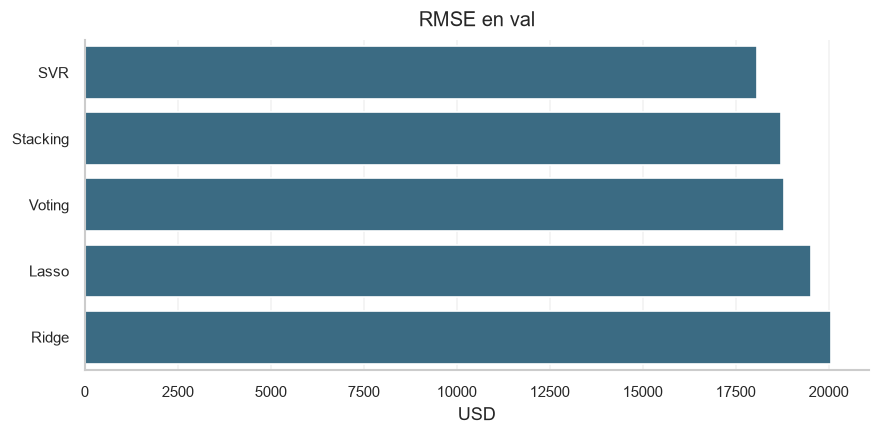

In [72]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
sns.barplot(
    data=comp,
    x="RMSE_val",
    y="Modelo",
    ax=ax,
    color=PLOT_PRIMARY,
    edgecolor=PLOT_EDGE,
)
style_axes(ax, "RMSE en val", "USD", "")
finalize_figure()


In [73]:
best_single = comp[comp["Modelo"].isin(top3)].iloc[0]
for ens in ["Voting", "Stacking"]:
    row = comp.loc[comp["Modelo"] == ens].iloc[0]
    delta = best_single["RMSE_val"] - row["RMSE_val"]
    speed = row["Tiempo_fit_s"] / max(best_single["Tiempo_fit_s"], 1e-9)
    print(
        f"{ens}: RMSE ${row['RMSE_val']:,.0f} vs mejor individual "
        f"({best_single['Modelo']}) ${best_single['RMSE_val']:,.0f} "
        f"→ Δ ${delta:,.0f} ({delta / best_single['RMSE_val'] * 100:.1f} %), "
        f"tiempo ×{speed:.1f}"
    )


Voting: RMSE $18,788 vs mejor individual (SVR) $18,087 → Δ $-701 (-3.9 %), tiempo ×1.5
Stacking: RMSE $18,730 vs mejor individual (SVR) $18,087 → Δ $-643 (-3.6 %), tiempo ×4.5


**¿Conviene el ensamble? (pregunta 15) — con los números de esta corrida: no.**

- **SVR (individual)** en val: RMSE **$18,087**, MAE **$12,628**, R² **0.940**, MAPE **8.0 %**, fit ~0.32 s.
- **Voting:** RMSE $18,788 → **3.9 % peor**, ~2× el tiempo de entrenamiento.
- **Stacking:** RMSE $18,730 → **3.6 % peor**, ~8× el tiempo.

Los coeficientes del meta-Ridge, **después del `StandardScaler`**, tienen magnitudes parecidas (contribuciones relativas ~35 % / 36 % / 30 % para SVR / Lasso / Ridge): los tres bases se parecen y **no hay diversidad de error** que el promedio o el apilamiento puedan explotar. Añadir complejidad solo encarece el mantenimiento. **Decisión: quedarse con un solo modelo (SVR por desempeño; Lasso si se prioriza interpretabilidad).**


## 13.0 Reportes finales


In [74]:
res = results_frame()
summary = (
    res[["Modelo", "RMSE_val", "MAE_val", "R2_val", "MAPE_val_%", "Tiempo_fit_s"]]
    .sort_values("RMSE_val")
    .round(2)
    .reset_index(drop=True)
)
display(summary)


,Modelo,RMSE_val,MAE_val,R2_val,MAPE_val_%,Tiempo_fit_s
0,SVR,18087.240,12628.390,0.940,8.040,0.260
1,Stacking,18730.060,13191.960,0.940,8.230,1.190
2,Voting,18788.180,13267.600,0.940,8.240,0.400
3,Lasso,19516.010,13881.470,0.930,8.520,0.120
4,Ridge,20076.750,14174.590,0.930,8.670,0.090
5,XGB,20156.380,14229.450,0.930,8.280,1.050
6,OLS,22604.540,15509.010,0.910,9.240,0.080
7,RF,22658.300,15690.610,0.910,9.700,4.200
8,MLP,26641.330,17524.060,0.870,10.050,2.300
9,Arbol,36118.800,24637.000,0.760,14.620,0.120


In [75]:
best_row = summary.iloc[0]
print(f"Modelo ingenuo: RMSE ${RMSE_BASE:,.0f}")
print(
    f"Mejor en val: {best_row['Modelo']} → RMSE ${best_row['RMSE_val']:,.0f}, "
    f"MAE ${best_row['MAE_val']:,.0f}, R² {best_row['R2_val']:.3f}, "
    f"MAPE {best_row['MAPE_val_%']:.1f} %"
)
print(
    f"Reducción del error vs ingenuo: "
    f"{(1 - best_row['RMSE_val'] / RMSE_BASE) * 100:.0f} %"
)
print("Top-3 por CV RMSE+MAE:", top3)


Modelo ingenuo: RMSE $74,324
Mejor en val: SVR → RMSE $18,087, MAE $12,628, R² 0.940, MAPE 8.0 %
Reducción del error vs ingenuo: 76 %
Top-3 por CV RMSE+MAE: ['SVR', 'Lasso', 'Ridge']


### 13.1 Reporte técnico (equipo de datos / ML)

**Recomendación de producción: desplegar SVR** (kernel RBF, pipeline con `log1p` + preprocesamiento versionado). Es el mejor en **val** y en la métrica de selección CV (RMSE+MAE).

1. **Métricas (val hold-out, n ≈ 292).** Ingenuo (media): RMSE **$74,324**. **SVR:** RMSE **$18,087**, MAE **$12,628**, R² **0.940**, MAPE **8.0 %** → **−76 %** de RMSE vs el ingenuo. Lasso: RMSE $19,516 (CV_RMSE mínimo entre individuos, $20,686). La diferencia SVR–Lasso en val (~$1.4k) es moderada frente al tamaño del hold-out; no la tratamos como un abismo, pero el ranking es estable a favor de SVR en val y en RMSE+MAE.
2. **Sesgo de selección.** Los CV_RMSE de la tabla son ligeramente optimistas (los hiperparámetros se eligieron con los mismos folds). Para aceptar/rechazar el modelo usamos **val**.
3. **Curvas.** Lineales y SVR con poca/moderada brecha y meseta; árbol/RF/XGB con sobreajuste marcado; MLP mejora con más datos pero no alcanza a SVR/Lasso.
4. **Ensambles.** Voting (−3.9 %) y Stacking (−3.6 %) **empeoran** el RMSE de val vs SVR y cuestan 2× / 8× en fit. **No adoptar.**
5. **Alternativa operativa.** Si negocio exige coeficientes legibles o un modelo más barato de explicar, **Lasso** es la opción razonable (casi el mismo CV RMSE, peor val pero interpretable).
6. **Operación.** Reentrenar periódico; recalcular `Age*` con el año corriente; no reintroducir `YrSold` bajo el supuesto estático; monitorear error por `Neighborhood` y por tramo de precio; vigilar `SaleType`/`SaleCondition` (entran en el top 10 de importancia).


### 13.2 Reporte ejecutivo (dirección inmobiliaria)

**En una frase:** el sistema estima el precio de una casa en segundos y, en nuestra muestra de validación (hold-out), se equivoca en promedio unos **$12,600** (RMSE ~$18,100), frente a ~$74,300 si solo usáramos el precio promedio histórico — una reducción del error de **alrededor del 76 %**.

- **Beneficios.** Valuaciones rápidas y consistentes; apoyo a listados y negociación; el modelo señala qué mueve el precio (sobre todo metros habitables y calidad, pero también cómo se estructura la venta).
- **Qué modelo usamos.** Recomendamos el **SVR** por precisión. Un modelo lineal (Lasso) queda cerca y es más fácil de explicar a un comité, si se prioriza transparencia sobre el último punto de error.
- **Qué no hacer.** Combinar varios modelos (votación/apilamiento) **no mejoró** la precisión en validación y sí encarece el mantenimiento; no aporta en este caso.
- **Riesgos.** No sustituye al valuador en casas atípicas o de lujo; el entrenamiento es de Ames (2006–2010) — hay que recalibrar con ventas locales recientes; conviene un margen de seguridad en montos altos.
- **Decisión sugerida.** Piloto en paralelo con valuadores, comparar estimaciones vs cierres reales durante un trimestre y decidir ampliación con evidencia.


## 14.0 Conclusiones


Incluye todos los comentarios y conclusiones de esta actividad. En particular, responde:

- ¿En qué casos el uso de LLMs fue de mayor provecho?
- ¿En cuáles casos tu intervención como experto en combinación con los LLM fue importante?


**Conclusiones técnicas (con los números de esta corrida)**

- El baseline ingenuo (media) tiene RMSE de val **$74,324**. El mejor predictor, **SVR**, baja a **$18,087** RMSE / **$12,628** MAE / R² **0.940** / MAPE **8.0 %** (−76 % de RMSE).
- Por CV_RMSE gana **Lasso** ($20,686), a ~$500 de SVR; por CV (RMSE+MAE) y por val gana **SVR**. La diferencia en val (~$1.4k, 292 casas) es relevante pero no “aplastante”: reportamos ambos criterios y recomendamos SVR para precisión y Lasso si hace falta interpretabilidad.
- **Voting y Stacking no conviene usarlos aquí:** +3.9 % y +3.6 % de RMSE vs SVR, con 2× y 8× el tiempo. Tras estandarizar, el meta-modelo reparte el peso de forma casi pareja entre SVR/Lasso/Ridge → poca diversidad de errores.
- Factores (permutación sobre Lasso): `GrLivArea`, `OverallQual`, `AgeHouse`, `OverallCond`, áreas de sótano; y en el top 10 también **`SaleType` / `SaleCondition`** (atributos de la *transacción*, no solo de la propiedad). El ΔRMSE de permutación mide sensibilidad, no el signo del efecto sobre el precio.
- Cumplir las restricciones temporales y tratar `NA` de `PoolQC`/`GarageType` como ausencia (validado con `PoolArea`/`GarageArea`) fue clave para no inventar amenidades ni filtrar tendencias de calendario.

**Uso de IA generativa (LLMs)**

Herramientas: Claude (Anthropic) y Cursor/Composer para scaffolding y alineación al estilo del repo.

_¿En qué casos fue de mayor provecho?_ Estructura vs rúbrica, pipelines sklearn, borradores de justificación.

_¿En qué casos fue importante la intervención experta?_ Diccionario de datos (NA = ausencia vs faltante real), no usar val para elegir hiperparámetros, interpretar que el ensemble no aporta, y **reescribir reportes/conclusiones con las cifras reales de la corrida** (un LLM genérico tiende a dejar plantillas del tipo “suelen dominar” / “revisar curvas”).

# Fin de la actividad — Predicción de Precios de Casas
